### Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from surprise import Dataset, Reader, SVD, NormalPredictor, accuracy, CoClustering, KNNBaseline
from surprise.model_selection import GridSearchCV
from collections import defaultdict
import time

### Functions

In [3]:
def build_train_and_test(X_train, X_test, rating_scale =(0, 5)):
    reader = Reader(rating_scale=rating_scale)
    train_data = Dataset.load_from_df(X_train[['review_profilename', 'brewery_style', 'review_overall']], reader)
    trainset = train_data.build_full_trainset()

    #Divide into known users and items, making sure to include all users and items in the test set are also in the training set
    known_users = set(trainset._raw2inner_id_users.keys())
    known_items = set(trainset._raw2inner_id_items.keys())
    X_test_known = X_test[X_test['review_profilename'].isin(known_users) & X_test['brewery_style'].isin(known_items)].copy()
    testset = list(X_test_known[['review_profilename', 'brewery_style', 'review_overall']].itertuples(index=False, name=None))
    return trainset, testset, X_test_known

def plot_abs_error_histogram(preds, title):
    errs = [abs(true_r - est) for (_, _, true_r, est, _) in preds]
    plt.figure(figsize=(6, 4))
    plt.hist(errs, bins=20, edgecolor='black')
    plt.title(title)
    plt.xlabel('Absolute Error')
    plt.ylabel('Frequency')
    plt.show()

def evaluate_from_preds(preds, beer_items, threshold=4.0, name="", fit_s=0.0, pred_s=0.0, k_top=5):
    #Regression metrics
    rmse = accuracy.rmse(preds, verbose=False)
    mae = accuracy.mae(preds, verbose=False)

    #Group predictions per user
    per_user = defaultdict(list)
    for uid, iid, true_r, est, _ in preds:
        per_user[uid].append((iid, true_r, est))
    
    #Precision, recall
    tp = fp = fn = 0

    #Coverage and ILS
    pred_pos_global = set() #All items ever predicted positively
    rec_items_global = set() #Items that were recommended
    user_has_rec = 0 #For user coverage
    precision_atk_list = []

    item_user_sets = (beer_items.groupby('brewery_style')['review_profilename'].apply(set).to_dict())
    ils_values = []

    for uid, user_ratings in per_user.items():
        for iid, true_r, est in user_ratings:
            is_true_pos = (true_r >= threshold)
            is_pred_pos = (est >= threshold)

            if is_pred_pos:
                pred_pos_global.add(iid)
                if is_true_pos:
                    tp += 1
                else:
                    fp += 1
            elif is_true_pos:
                fn += 1

        #Sort all items for a user by predicted rating
        lst_sorted = sorted(user_ratings, key=lambda x: x[2], reverse=True)
        recset = [iid for (iid, true_r, est) in lst_sorted if est >= threshold][:k_top]

        if recset:
            user_has_rec += 1
            rec_items_global.update(recset)

            #Run ILS on the user's recommendations
            if len(recset) > 1:
                sims = []
                for i in range(len(recset)):
                    iu = item_user_sets.get(recset[i])
                    if not iu:
                        continue
                    for j in range(i + 1, len(recset)):
                        ju = item_user_sets.get(recset[j])
                        if not ju:
                            continue
                        intersection = len(iu & ju)
                        union   = len(iu | ju)
                        if union > 0:
                            sims.append(intersection / union)
                if sims:
                    ils_values.append(np.mean(sims))
            
        #Precision@K
        topk = lst_sorted[:k_top]
        hits_topk = sum(1 for (_, true_r, _) in topk if true_r >= threshold)
        precision_atk_list.append(hits_topk / k_top)
    
    #Get overall precision, recall, F1
    precision_overall = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall_overall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1_overall = (2 * precision_overall * recall_overall) / (precision_overall + recall_overall) if (precision_overall + recall_overall) > 0 else 0.0

    precision_atk = float(np.mean(precision_atk_list)) if precision_atk_list else 0.0

    #Coverage
    user_coverage = (user_has_rec / len(per_user) if per_user else 0.0)

    if pred_pos_global:
        conditional_coverage = len(rec_items_global) / len(pred_pos_global)
    else:
        conditional_coverage = 0.0

    #Overall ILS
    ils = float(np.mean(ils_values)) if ils_values else 0.0

    #Return all metrics
    return {
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "Precision": precision_overall,
        "Precision@5": precision_atk,
        "Recall": recall_overall,
        "F1": f1_overall,
        "User Coverage": user_coverage,
        "Conditional Coverage": conditional_coverage,
        "ILS": ils,
        "Train Time (s)": fit_s,
        "Predict Time (s)": pred_s
    }

def evaluate_model(algo, trainset, testset, beer_items, threshold=4.0, name="", k_top=5):
    #Get fit and prediction times
    start_fit = time.time()
    algo.fit(trainset)
    fit_time = time.time() - start_fit

    start_pred = time.time()
    preds = algo.test(testset)
    pred_time = time.time() - start_pred

    metrics = evaluate_from_preds(preds, beer_items, threshold=threshold, name=name, fit_s=fit_time, pred_s=pred_time, k_top=k_top)
    return metrics, preds

def build_hybrid_preds_svd_popularity(svd_preds, pop_preds, user_review_counts, low=11, high=45):
    hybrid_preds = []

    for p_svd, p_pop in zip(svd_preds, pop_preds):
        uid_svd, iid_svd, true_r, est_svd, _ = p_svd
        uid_pop, iid_pop, _, est_pop, _ = p_pop
        #In case of mismatched predictions, but surprise should not let that happen and preserve the order
        assert uid_svd == uid_pop and iid_svd == iid_pop, "Mismatched predictions"

        n_reviews = user_review_counts.get(uid_svd, 0)

        if low <= n_reviews <= high:
            est = est_pop
        else:
            est = est_svd
        
        hybrid_preds.append((uid_svd, iid_svd, true_r, est, None))

    return hybrid_preds

### Data Loading and Preprocessing

In [4]:
#Loading the dataset and dropping missing values
beers = pd.read_csv('beer_reviews.csv')
beers.dropna(inplace=True)

#Ensure numeric types for ratings and create brewery_style column
beers['review_overall'] = pd.to_numeric(beers['review_overall'], errors='coerce')
beers.dropna(subset=['review_overall'], inplace=True)
beers['brewery_style'] = beers['brewery_id'].astype(str) + "_" + beers['beer_style'].astype(str)

#Keep only needed columns
beer_items = beers[['review_profilename', 'review_overall', 'brewery_style']]

#Filter users with at least 11 reviews
user_counts = beer_items['review_profilename'].value_counts()
beer_items = beer_items[beer_items['review_profilename'].isin(user_counts[user_counts >= 11].index)]

#Used later, number of reviews per user
user_review_counts = beer_items['review_profilename'].value_counts().to_dict()

#Split into training and test sets
X = beer_items.copy()
y = beer_items['review_overall']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

#Build the surprise train and test sets, also filtering test set to known users and items
trainset, testset, X_test_known = build_train_and_test(X_train, X_test, rating_scale=(0, 5))

print({
    "users_in_train": trainset.n_users,
    "items_in_train": trainset.n_items,
    "ratings_in_train": trainset.n_ratings,
    "test_rows": len(X_test),
    "test_rows_known": len(X_test_known),
    "kept_ratio": round(len(X_test_known) / len(X_test), 3)
})

{'users_in_train': 10067, 'items_in_train': 30464, 'ratings_in_train': 1091125, 'test_rows': 363709, 'test_rows_known': 360658, 'kept_ratio': 0.992}


### EDA

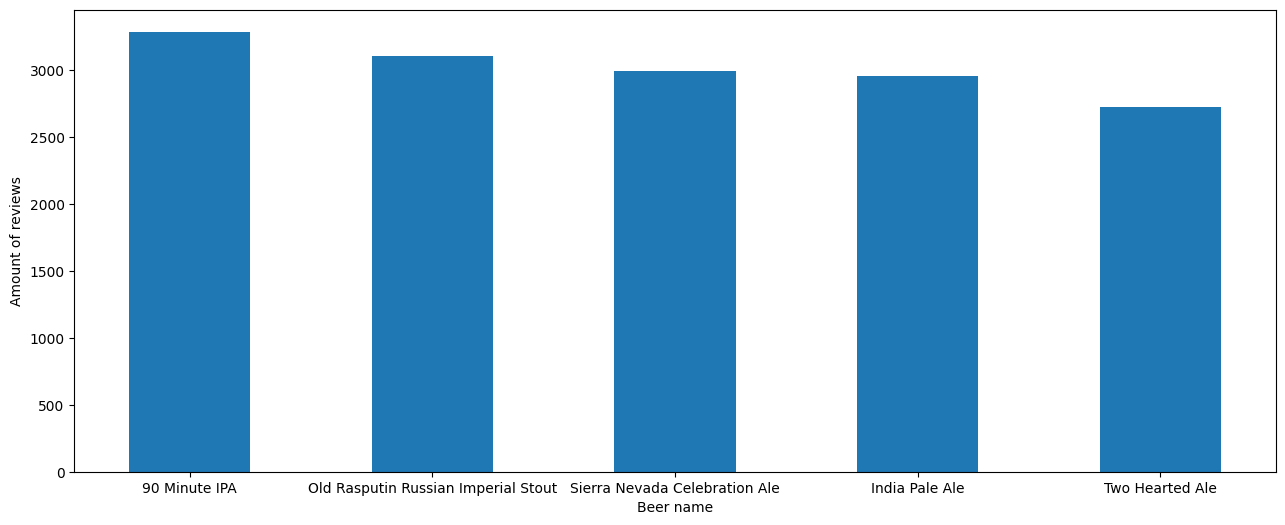

In [10]:
beer_count = beers["beer_name"].value_counts()
beer_count_x = beer_count[0:5].keys()
beer_count_y = beer_count[0:5].values
plt.figure(figsize=(15.5,6))
plt.bar(beer_count_x, beer_count_y, width=0.5)
plt.xlabel("Beer name")
plt.ylabel("Amount of reviews")
plt.show()

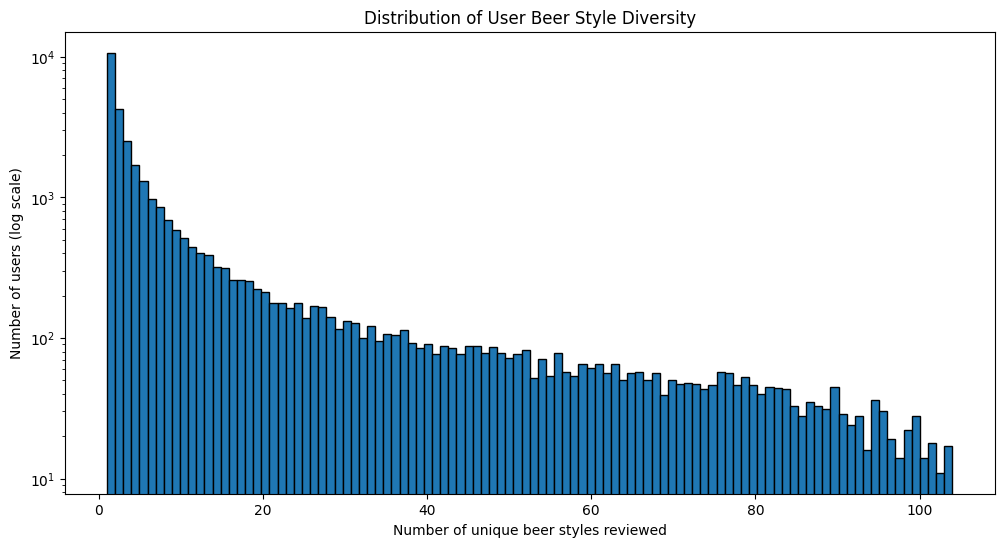

In [6]:
user_style_counts = beers.groupby('review_profilename')['beer_style'].nunique()
plt.figure(figsize=(12,6))
plt.hist(user_style_counts, bins=104, edgecolor='black', log=True)
plt.xlabel('Number of unique beer styles reviewed')
plt.ylabel('Number of users (log scale)')
plt.title('Distribution of User Beer Style Diversity')
plt.show()

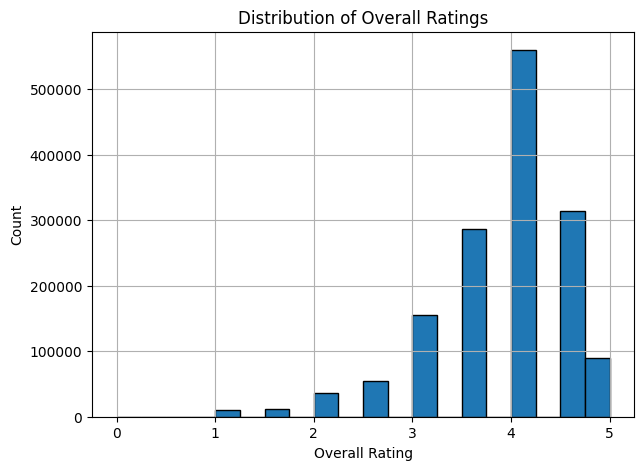

Sparsity (train user–item pivot): 99.6766%
Mean: 3.818422926601935
Median: 4.0
Std: 0.7085677818273737

Percentiles:
25th percentile: 3.5
37th percentile: 4.0
50th percentile: 4.0
60th percentile: 4.0
70th percentile: 4.0
75th percentile: 4.5
80th percentile: 4.5
90th percentile: 4.5

Positive rating percentages at different thresholds:
Threshold 3.5: 82.3% of ratings counted as positive
Threshold 4.0: 63.1% of ratings counted as positive
Threshold 4.5: 25.9% of ratings counted as positive


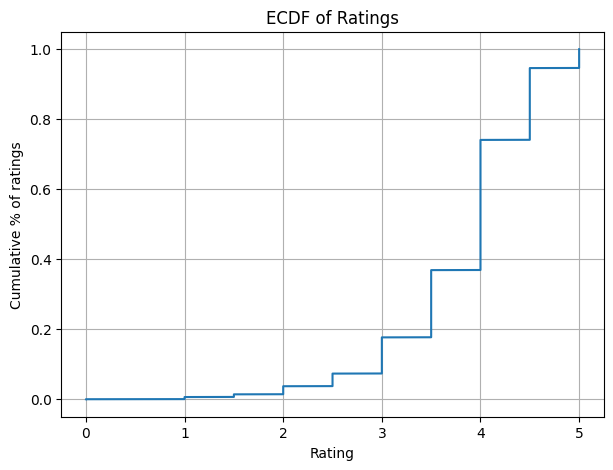

In [5]:
#Distribution of overall ratings
plt.figure(figsize=(7,5))
beers['review_overall'].hist(bins=20, edgecolor="black")
plt.title("Distribution of Overall Ratings")
plt.xlabel("Overall Rating")
plt.ylabel("Count")
plt.show()

#Sparsity of user–item matrix
r_matrix = X_train.pivot_table(
    values="review_overall",
    index="review_profilename",
    columns="brewery_style"
)
sparsity = np.count_nonzero(r_matrix.isna()) / r_matrix.size
print(f"Sparsity (train user–item pivot): {sparsity:.4%}")

ratings = beer_items['review_overall']
print("Mean:", ratings.mean())
print("Median:", ratings.median())
print("Std:", ratings.std())

print("\nPercentiles:")
for p in [0.25, 0.37, 0.5, 0.6, 0.7, 0.75, 0.8, 0.9]:
    print(f"{p*100:.0f}th percentile: {ratings.quantile(p)}")

print("\nPositive rating percentages at different thresholds:")
for t in [3.5, 4.0, 4.5]:
    pct = (ratings >= t).mean() * 100
    print(f"Threshold {t}: {pct:.1f}% of ratings counted as positive")

#ECDF of ratings
sorted_r = np.sort(ratings)
y_ecdf = np.arange(1, len(sorted_r)+1) / len(sorted_r)

plt.figure(figsize=(7,5))
plt.plot(sorted_r, y_ecdf)
plt.xlabel("Rating")
plt.ylabel("Cumulative % of ratings")
plt.title("ECDF of Ratings")
plt.grid(True)
plt.show()

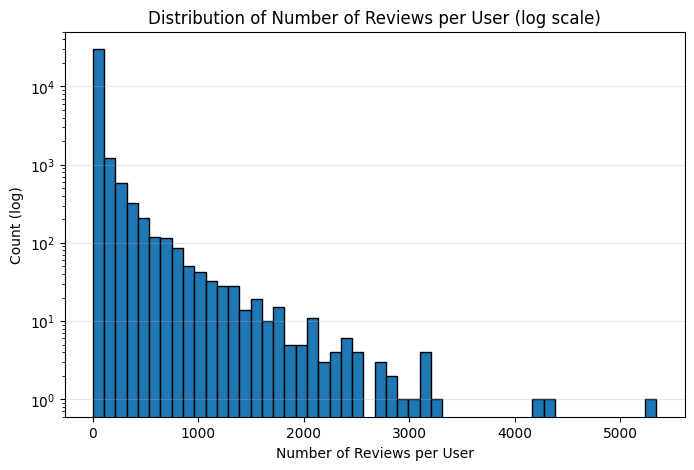

Users total: 32,908
Median reviews per user: 3.0
Average reviews per user: 46.14
Max reviews by a user: 5,346 (User: northyorksammy)
User review count percentiles:
0.50      3.00
0.70     11.00
0.75     16.00
0.85     45.00
0.90     91.00
0.95    225.00
0.99    816.79
Name: count, dtype: float64

Total users: 32908


In [7]:
#Number of reviews per user
user_counts = beers['review_profilename'].value_counts()

plt.figure(figsize=(8,5))
plt.hist(user_counts, bins=50, log=True, edgecolor="black")
plt.title("Distribution of Number of Reviews per User (log scale)")
plt.xlabel("Number of Reviews per User")
plt.ylabel("Count (log)")
plt.grid(axis="y", alpha=0.3)
plt.show()

print(f"Users total: {len(user_counts):,}")
print(f"Median reviews per user: {user_counts.median()}")
print(f"Average reviews per user: {round(user_counts.mean(),2)}")
print(f"Max reviews by a user: {user_counts.max():,} (User: {user_counts.idxmax()})")

percentiles = user_counts.quantile([0.5, 0.7,0.75, 0.85, 0.90, 0.95, 0.99])
print("User review count percentiles:")
print(percentiles)
print(f"\nTotal users: {len(user_counts)}")

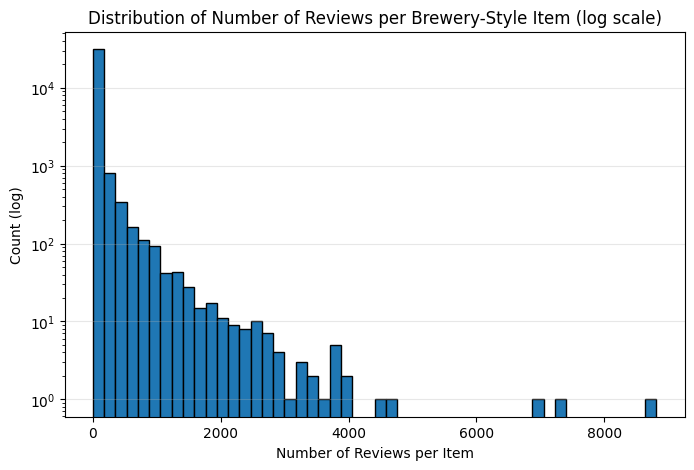

Items total: 33,072
Median reviews per item: 4.0
Average reviews per item: 43.99
Max reviews for an item: 8,816 (Item: 140_American IPA)


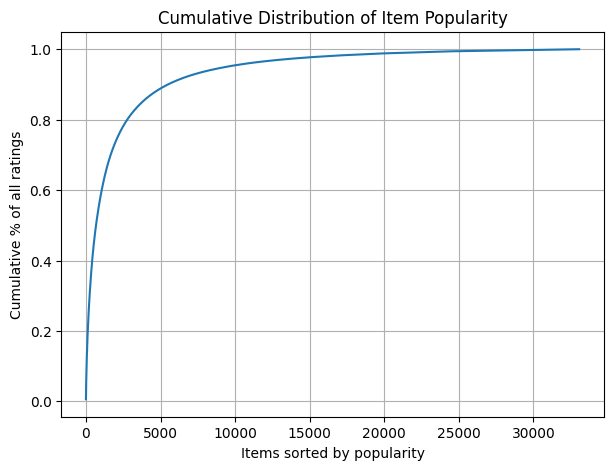

Top 5% of items cover 69.9% of all ratings.
Top 10% of items cover 83.0% of all ratings.
Top 20% of items cover 92.0% of all ratings.


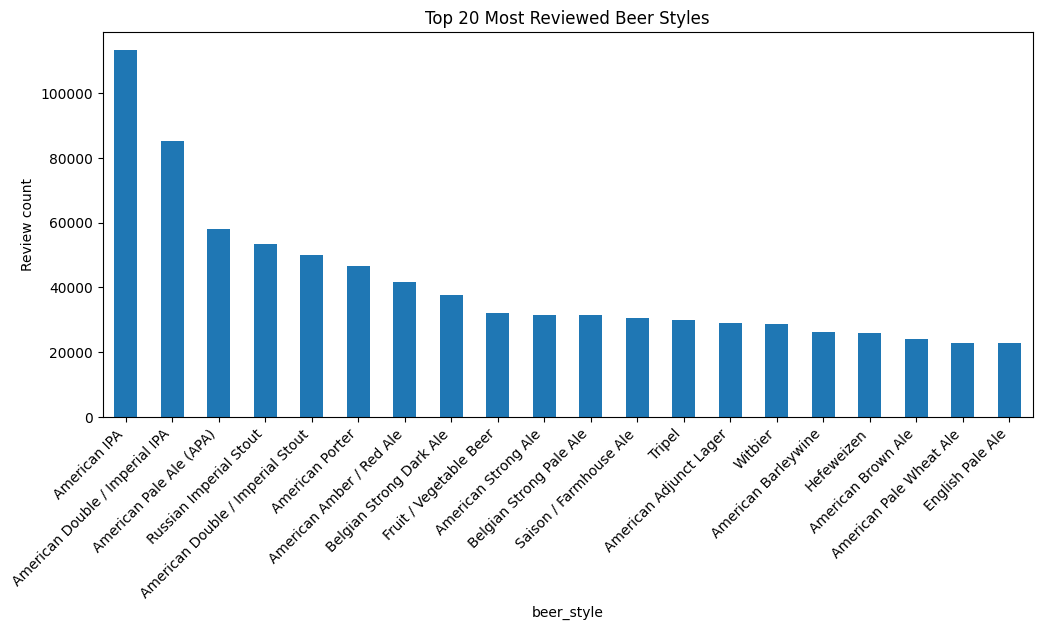

In [11]:
#Number of reviews per item
item_counts = beer_items['brewery_style'].value_counts()

plt.figure(figsize=(8,5))
plt.hist(item_counts, bins=50, log=True, edgecolor="black")
plt.title("Distribution of Number of Reviews per Brewery-Style Item (log scale)")
plt.xlabel("Number of Reviews per Item")
plt.ylabel("Count (log)")
plt.grid(axis="y", alpha=0.3)
plt.show()

print(f"Items total: {len(item_counts):,}")
print(f"Median reviews per item: {item_counts.median()}")
print(f"Average reviews per item: {round(item_counts.mean(),2)}")
print(f"Max reviews for an item: {item_counts.max():,} (Item: {item_counts.idxmax()})")

#Cumulative popularity curve
item_counts = beer_items["brewery_style"].value_counts()
cum = item_counts.cumsum() / item_counts.sum()

plt.figure(figsize=(7,5))
plt.plot(cum.values)
plt.title("Cumulative Distribution of Item Popularity")
plt.xlabel("Items sorted by popularity")
plt.ylabel("Cumulative % of all ratings")
plt.grid(True)
plt.show()

print(f"Top 5% of items cover {(cum.iloc[int(len(cum) * 0.05)] * 100):.1f}% of all ratings.")
print(f"Top 10% of items cover {(cum.iloc[int(len(cum) * 0.10)] * 100):.1f}% of all ratings.")
print(f"Top 20% of items cover {(cum.iloc[int(len(cum) * 0.20)] * 100):.1f}% of all ratings.")

beers["beer_style"].value_counts().head(20).plot(kind="bar", figsize=(12,5))
plt.title("Top 20 Most Reviewed Beer Styles")
plt.ylabel("Review count")
plt.xticks(rotation=45, ha="right")
plt.show()

### Baselines

In [8]:
THRESH = 4.0   #Positive if rating >= 4.0
K_TOP  = 5     #For Precision@5 etc

=== Random baseline ===
{'Model': 'Random', 'RMSE': 0.981308174673376, 'MAE': 0.7732989711943665, 'Precision': 0.6339687582737622, 'Precision@5': 0.5971026076531123, 'Recall': 0.3988244472886021, 'F1': 0.48962800733976547, 'User Coverage': 0.9303626735937656, 'Conditional Coverage': 0.4784055613074989, 'ILS': 0.11441066028734131, 'Train Time (s)': 0.6705901622772217, 'Predict Time (s)': 1.5232150554656982}


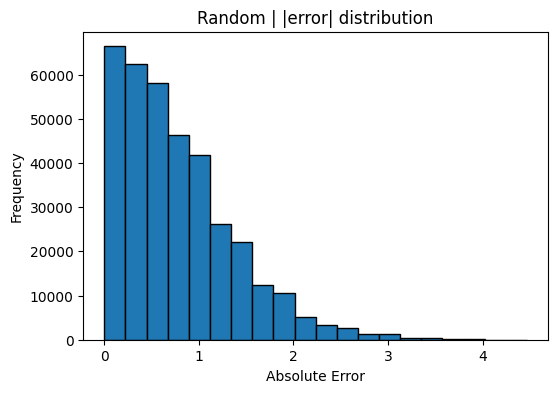

In [10]:
rand_algo = NormalPredictor()
rand_metrics, rand_preds = evaluate_model(rand_algo, trainset, testset, beer_items, threshold=THRESH, name="Random", k_top=K_TOP)
print("=== Random baseline ===")
print(rand_metrics)
plot_abs_error_histogram(rand_preds, "Random | |error| distribution")

=== Popularity baseline ===
{'Model': 'Popularity', 'RMSE': 1.1002127471002996, 'MAE': 0.8807052664851467, 'Precision': 0.6370912403918787, 'Precision@5': 0.6239784194225197, 'Recall': 0.9685379665830952, 'F1': 0.7686046713855893, 'User Coverage': 0.999400539514437, 'Conditional Coverage': 0.3499594484995945, 'ILS': 0.17374397054102242, 'Train Time (s)': 0.0, 'Predict Time (s)': 0.0}


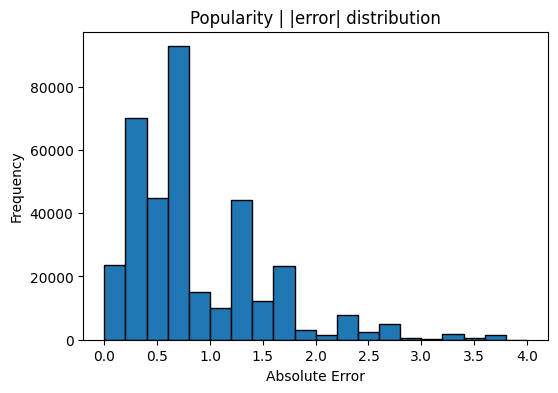

In [11]:
item_counts = beer_items['brewery_style'].value_counts()
n_items = len(item_counts)
top5_items = item_counts.head(5).index.tolist()
item_ranks = item_counts.rank(method='first', ascending=False)
item_percentiles = (item_ranks - 1) / n_items

#Fixed scores based on popularity percentiles
buckets = [
    (0.05, 4.8),
    (0.15, 4.4),
    (0.30, 4.0),
    (0.60, 3.5),
    (1.00, 2.5)
]

def popularity_score(iid):
    if iid in top5_items:
        return 5.0
    percentile = item_percentiles[iid]
    for cutoff, score in buckets:
        if percentile <= cutoff:
            return score

pop_preds = []
for uid, iid, true_r in testset:
    est = popularity_score(iid) if iid in item_counts.index else 3.0
    pop_preds.append((uid, iid, true_r, est, None))

pop_metrics = evaluate_from_preds(pop_preds, beer_items, threshold=THRESH, name="Popularity", fit_s=0.0, pred_s=0.0, k_top=K_TOP)
print("=== Popularity baseline ===")
print(pop_metrics)
plot_abs_error_histogram(pop_preds, "Popularity | |error| distribution")


### Grid Search

In [12]:
reader = Reader(rating_scale=(0, 5))
data = Dataset.load_from_df(beer_items[['review_profilename', 'brewery_style', 'review_overall']],reader)

In [ ]:
param_grid_svd = {
    "n_factors": [30, 50, 100],
    "n_epochs": [20, 30, 40],
    "lr_all": [0.002, 0.005, 0.008],
    "reg_all": [0.02, 0.05, 0.08],
}

gs_svd = GridSearchCV(SVD, param_grid_svd, measures=["rmse"], cv=3, n_jobs=-1, joblib_verbose=1)
gs_svd.fit(data)

print("Best SVD RMSE:", gs_svd.best_score["rmse"])
print("Best SVD params:", gs_svd.best_params["rmse"])

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=-1)]: Done  38 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done 188 tasks      | elapsed:  9.4min
[Parallel(n_jobs=-1)]: Done 243 out of 243 | elapsed: 13.4min finished


Best SVD RMSE: 0.592790105673202
Best SVD params: {'n_factors': 100, 'n_epochs': 40, 'lr_all': 0.008, 'reg_all': 0.05}


In [16]:
param_grid_coc = {
    "n_cltr_u": [3, 5, 7],
    "n_cltr_i": [3, 5, 7],
    "n_epochs": [10, 20, 30],
}

gs_coc = GridSearchCV(CoClustering, param_grid_coc, measures=["rmse"], cv=3)
gs_coc.fit(data)

print("Best CoC RMSE:", gs_coc.best_score["rmse"])
print("Best CoC Params:", gs_coc.best_params["rmse"])

Best CoC RMSE: 0.6570540494618652
Best CoC Params: {'n_cltr_u': 3, 'n_cltr_i': 5, 'n_epochs': 30}


In [17]:
param_grid_knn = {
    "k": [30, 50, 70],
    "min_k": [3, 5, 8],
    "sim_options": {
        "name": ["msd"],
        "user_based": [False]
    }
}

gs_knn = GridSearchCV(KNNBaseline,param_grid_knn,measures=["rmse"],cv=3)
gs_knn.fit(data)

print("Best KNN RMSE:", gs_knn.best_score["rmse"])
print("Best KNN Params:", gs_knn.best_params["rmse"])


Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the msd similarity matr

### SVD

=== SVD Model ===
{'Model': 'SVD', 'RMSE': 0.592085675401233, 'MAE': 0.4432972805385773, 'Precision': 0.8563943479237186, 'Precision@5': 0.7216105505045459, 'Recall': 0.4513386047653278, 'F1': 0.5911357197599221, 'User Coverage': 0.8404436007593166, 'Conditional Coverage': 0.4177386594448206, 'ILS': 0.18167405580536303, 'Train Time (s)': 24.62060022354126, 'Predict Time (s)': 2.1622631549835205}


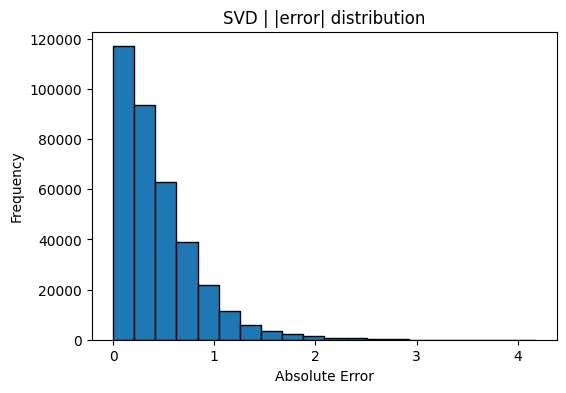


SVD – predicted ratings summary:
count    360658.000000
mean          3.821553
std           0.379328
min           1.140232
25%           3.641981
50%           3.871271
75%           4.070413
max           5.000000
Name: predicted_rating, dtype: float64

SVD – true ratings summary (test set):
count    360658.000000
mean          3.820858
std           0.708673
min           0.000000
25%           3.500000
50%           4.000000
75%           4.500000
max           5.000000
Name: true_rating, dtype: float64

=== Count of ratings >= 4.0 (SVD) ===
True ratings ≥ 4.0: 228148  (63.26%)
Predicted ratings ≥ 4.0: 120239  (33.34%)



In [18]:
svd = SVD(n_factors=100, n_epochs=40, lr_all=0.008, reg_all=0.05, random_state=42)
svd_metrics, svd_preds = evaluate_model(svd, trainset, testset, beer_items, threshold=THRESH, name="SVD", k_top=K_TOP)
print("=== SVD Model ===")
print(svd_metrics)
plot_abs_error_histogram(svd_preds, "SVD | |error| distribution")

#Distribution analysis
svd_pred_ratings = pd.Series([p.est for p in svd_preds], name="predicted_rating")
svd_true_ratings = pd.Series([p.r_ui for p in svd_preds], name="true_rating")

print("\nSVD – predicted ratings summary:")
print(svd_pred_ratings.describe())
print("\nSVD – true ratings summary (test set):")
print(svd_true_ratings.describe())

true_pos = (svd_true_ratings >= THRESH).sum()
pred_pos = (svd_pred_ratings >= THRESH).sum()
true_pct = true_pos / len(svd_true_ratings) * 100
pred_pct = pred_pos / len(svd_pred_ratings) * 100

print(f"\n=== Count of ratings >= {THRESH} (SVD) ===")
print(f"True ratings ≥ {THRESH}: {true_pos}  ({true_pct:.2f}%)")
print(f"Predicted ratings ≥ {THRESH}: {pred_pos}  ({pred_pct:.2f}%)\n")

### Co-Clustering

=== Co-Clustering ===
{'Model': 'CoClustering', 'RMSE': 0.6553882404469351, 'MAE': 0.5114296103238155, 'Precision': 0.8890411886147493, 'Precision@5': 0.715755819762214, 'Recall': 0.23027596121815663, 'F1': 0.365803051085844, 'User Coverage': 0.6391247876910781, 'Conditional Coverage': 0.5318829707426856, 'ILS': 0.18245440751177772, 'Train Time (s)': 46.620959520339966, 'Predict Time (s)': 1.7816290855407715}


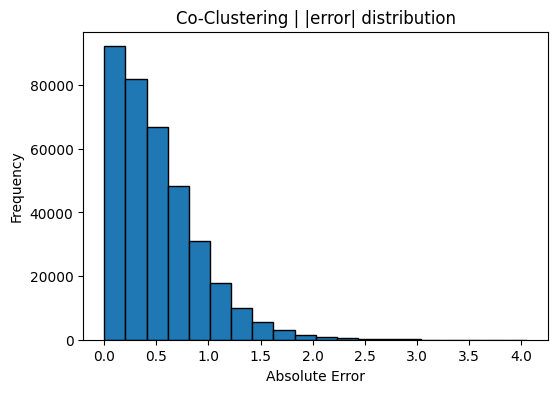


Co-Clustering – predicted ratings summary:
count    360658.000000
mean          3.600802
std           0.464184
min           0.187930
25%           3.384923
50%           3.678803
75%           3.906825
max           5.000000
Name: predicted_rating, dtype: float64

Co-Clustering – true ratings summary (test set):
count    360658.000000
mean          3.820858
std           0.708673
min           0.000000
25%           3.500000
50%           4.000000
75%           4.500000
max           5.000000
Name: true_rating, dtype: float64

=== Count of ratings >= 4.0 ===
True ratings ≥ 4.0: 228148  (63.26%)
Predicted ratings ≥ 4.0: 59094  (16.39%)



In [19]:
coc = CoClustering(n_cltr_u=3, n_cltr_i=5, n_epochs=30, random_state=42)
coc_metrics, coc_preds = evaluate_model(coc, trainset, testset, beer_items,threshold=THRESH, name="CoClustering", k_top=K_TOP)
print("=== Co-Clustering ===")
print(coc_metrics)
plot_abs_error_histogram(coc_preds, "Co-Clustering | |error| distribution")

#Distribution analysis
coc_pred_ratings = pd.Series([p.est for p in coc_preds], name="predicted_rating")
coc_true_ratings = pd.Series([p.r_ui for p in coc_preds], name="true_rating")

print("\nCo-Clustering – predicted ratings summary:")
print(coc_pred_ratings.describe())
print("\nCo-Clustering – true ratings summary (test set):")
print(coc_true_ratings.describe())

true_pos = (coc_true_ratings >= THRESH).sum()
pred_pos = (coc_pred_ratings >= THRESH).sum()
true_pct = true_pos / len(coc_true_ratings) * 100
pred_pct = pred_pos / len(coc_pred_ratings) * 100

print(f"\n=== Count of ratings >= {THRESH} ===")
print(f"True ratings ≥ {THRESH}: {true_pos}  ({true_pct:.2f}%)")
print(f"Predicted ratings ≥ {THRESH}: {pred_pos}  ({pred_pct:.2f}%)\n")

### KNN

Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.
=== KNNBaseline ===
{'Model': 'KNNBaseline', 'RMSE': 0.596618392987684, 'MAE': 0.4451209554964849, 'Precision': 0.8481308228140696, 'Precision@5': 0.7198321510640423, 'Recall': 0.4744332626190017, 'F1': 0.6084869199569386, 'User Coverage': 0.8426416225397143, 'Conditional Coverage': 0.3595900439238653, 'ILS': 0.2006210362078354, 'Train Time (s)': 66.04739141464233, 'Predict Time (s)': 135.9589762687683}


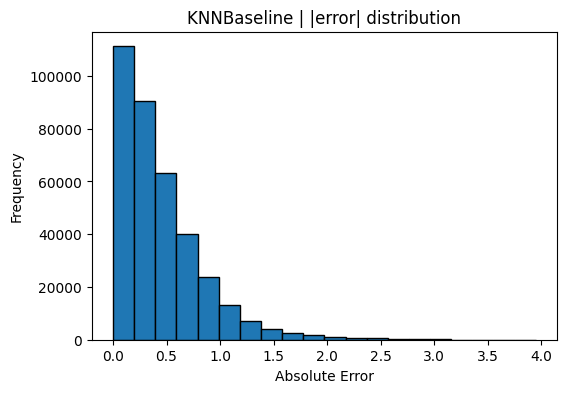


KNN – predicted ratings summary:
count    360658.000000
mean          3.834122
std           0.396101
min           0.574305
25%           3.645939
50%           3.881877
75%           4.090122
max           5.000000
Name: predicted_rating, dtype: float64

KNN – true ratings summary (test set):
count    360658.000000
mean          3.820858
std           0.708673
min           0.000000
25%           3.500000
50%           4.000000
75%           4.500000
max           5.000000
Name: true_rating, dtype: float64

=== Count of ratings >= 4.0 ===
True ratings ≥ 4.0: 228148  (63.26%)
Predicted ratings ≥ 4.0: 127623  (35.39%)



In [20]:
knn = KNNBaseline(k=70,min_k=8,sim_options={
        "name": "msd",
        "user_based": False,
        "min_support": 3
    })

knn_metrics, knn_preds = evaluate_model(knn, trainset, testset, beer_items, threshold=THRESH, name="KNNBaseline", k_top=K_TOP)
print("=== KNNBaseline ===")
print(knn_metrics)
plot_abs_error_histogram(knn_preds, "KNNBaseline | |error| distribution")

knn_pred_ratings = pd.Series([p.est for p in knn_preds], name="predicted_rating")
knn_true_ratings = pd.Series([p.r_ui for p in knn_preds], name="true_rating")

print("\nKNN – predicted ratings summary:")
print(knn_pred_ratings.describe())
print("\nKNN – true ratings summary (test set):")
print(knn_true_ratings.describe())

true_pos = (knn_true_ratings >= THRESH).sum()
pred_pos = (knn_pred_ratings >= THRESH).sum()
true_pct = true_pos / len(knn_true_ratings) * 100
pred_pct = pred_pos / len(knn_pred_ratings) * 100

print(f"\n=== Count of ratings >= {THRESH} ===")
print(f"True ratings ≥ {THRESH}: {true_pos}  ({true_pct:.2f}%)")
print(f"Predicted ratings ≥ {THRESH}: {pred_pos}  ({pred_pct:.2f}%)\n")

### Comparison

In [21]:
comparison_df = pd.DataFrame([rand_metrics, pop_metrics, svd_metrics, coc_metrics, knn_metrics]).set_index("Model")

cols = ["RMSE", "MAE","Precision", "Precision@5", "Recall", "F1", "User Coverage", "Conditional Coverage", "ILS","Train Time (s)", "Predict Time (s)"]
comparison_df = comparison_df[cols].round(3)

try:
    from IPython.display import display
    display(comparison_df.style.set_caption("Comparison: Random vs Popularity vs SVD vs Co-Clustering vs KNNBaseline"))
except Exception:
    print(comparison_df)

,RMSE,MAE,Precision,Precision@5,Recall,F1,User Coverage,Conditional Coverage,ILS,Train Time (s),Predict Time (s)
Model,,,,,,,,,,,
Random,0.981000,0.773000,0.634000,0.597000,0.399000,0.490000,0.930000,0.478000,0.114000,0.671000,1.523000
Popularity,1.100000,0.881000,0.637000,0.624000,0.969000,0.769000,0.999000,0.350000,0.174000,0.000000,0.000000
SVD,0.592000,0.443000,0.856000,0.722000,0.451000,0.591000,0.840000,0.418000,0.182000,24.621000,2.162000
CoClustering,0.655000,0.511000,0.889000,0.716000,0.230000,0.366000,0.639000,0.532000,0.182000,46.621000,1.782000
KNNBaseline,0.597000,0.445000,0.848000,0.720000,0.474000,0.608000,0.843000,0.360000,0.201000,66.047000,135.959000


### Hybrid Alternative

=== Hybrid (Popularity for 11–45, SVD for >45) ===
{'Model': 'Hybrid', 'RMSE': 0.647345527482998, 'MAE': 0.4740519469789622, 'Precision': 0.8186966555551486, 'Precision@5': 0.704865620941153, 'Recall': 0.48980486350965163, 'F1': 0.6129172917072315, 'User Coverage': 0.9705265261264862, 'Conditional Coverage': 0.4852990875295708, 'ILS': 0.16522351733347138, 'Train Time (s)': 24.62060022354126, 'Predict Time (s)': 2.1622631549835205}


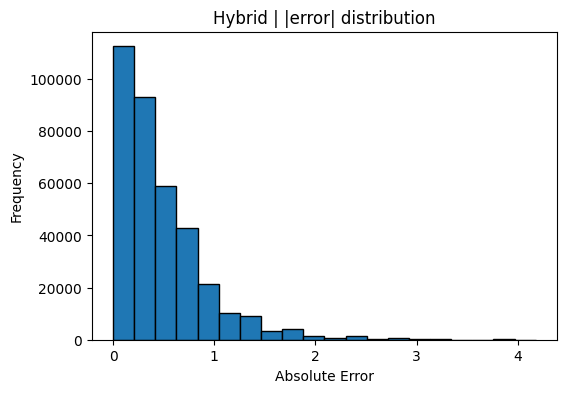

In [22]:
LOW = 11
HIGH = 45

hybrid_preds = build_hybrid_preds_svd_popularity(svd_preds, pop_preds, user_review_counts, low=LOW, high=HIGH)

hybrid_metrics = evaluate_from_preds(hybrid_preds,beer_items,threshold=THRESH,name=f"Hybrid",fit_s=svd_metrics["Train Time (s)"], pred_s=svd_metrics["Predict Time (s)"],  k_top=K_TOP)

print("=== Hybrid (Popularity for 11–45, SVD for >45) ===")
print(hybrid_metrics)
plot_abs_error_histogram(hybrid_preds, "Hybrid | |error| distribution")

In [23]:
comparison_df = pd.DataFrame([hybrid_metrics, svd_metrics]).set_index("Model")

cols = ["RMSE", "MAE","Precision", "Precision@5", "Recall", "F1","User Coverage", "Conditional Coverage", "ILS","Train Time (s)", "Predict Time (s)"]
comparison_df = comparison_df[cols].round(3)

try:
    from IPython.display import display
    display(comparison_df.style.set_caption("Hybrid Model Metrics vs SVD"))
except Exception:
    print(comparison_df)

,RMSE,MAE,Precision,Precision@5,Recall,F1,User Coverage,Conditional Coverage,ILS,Train Time (s),Predict Time (s)
Model,,,,,,,,,,,
Hybrid,0.647000,0.474000,0.819000,0.705000,0.490000,0.613000,0.971000,0.485000,0.165000,24.621000,2.162000
SVD,0.592000,0.443000,0.856000,0.722000,0.451000,0.591000,0.840000,0.418000,0.182000,24.621000,2.162000
